# Budget personnel : où part l'argent ?

**Problème :** Calculer les dépenses par catégorie et suivre leur évolution. Anomalies : montant négatif, catégorie manquante, doublon.

Les données sont synthétiques. Exécute les cellules dans l'ordre. Le fichier `donnees.xlsx` doit rester dans le même dossier que ce notebook.

## Étape 1 — Lire et explorer les données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
df = pd.read_excel("donnees.xlsx", sheet_name="donnees")
print("Dimensions :", df.shape)
display(df.head())
display(df.sample(min(5, len(df)), random_state=1))


Dimensions : (31, 5)


,date,categorie,description,montant_mad,mode_paiement
0,2026-01-01,Repas,Cinéma,134.35,Virement
1,2026-01-04,Téléphone,Internet,157.98,Virement
2,2026-01-07,Téléphone,Livres,274.13,Virement
3,2026-01-10,Repas,Internet,331.70,Carte
4,2026-01-13,Téléphone,Livres,-50.00,Espèces


,date,categorie,description,montant_mad,mode_paiement
27,2026-03-23,Loisirs,Livres,78.18,Virement
3,2026-01-10,Repas,Internet,331.70,Carte
19,2026-02-27,Repas,Internet,327.50,Espèces
23,2026-03-11,Loisirs,Cinéma,181.97,Virement
22,2026-03-08,Études,Livres,345.53,Carte


## Étape 2 — Comprendre la structure

In [2]:
df.info()
display(df.describe(include="all").T)
print("Colonnes :", df.columns.tolist())


<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           31 non-null     datetime64[us]
 1   categorie      30 non-null     str           
 2   description    31 non-null     str           
 3   montant_mad    31 non-null     float64       
 4   mode_paiement  31 non-null     str           
dtypes: datetime64[us](1), float64(1), str(3)
memory usage: 1.3 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,31,NaN,NaN,NaN,2026-02-12 18:34:50.322580,2026-01-01 00:00:00,2026-01-22 00:00:00,2026-02-12 00:00:00,2026-03-06 12:00:00,2026-03-29 00:00:00,NaN
categorie,30,5,Repas,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,31,5,Livres,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
montant_mad,31.0,NaN,NaN,NaN,167.971935,-50.0,61.07,174.87,267.85,347.28,117.039885
mode_paiement,31,3,Virement,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Colonnes : ['date', 'categorie', 'description', 'montant_mad', 'mode_paiement']


## Étape 3 — Détecter les anomalies

In [3]:
print("Valeurs manquantes :")
display(df.isna().sum())
print("Lignes dupliquées :", df.duplicated().sum())
for col in df.select_dtypes(include=["object", "string"]).columns:
    print(f"\\n{col} :", df[col].dropna().astype(str).unique()[:15])


Valeurs manquantes :


date             0
categorie        1
description      0
montant_mad      0
mode_paiement    0
dtype: int64

Lignes dupliquées : 1
\ncategorie : <StringArray>
['Repas', 'Téléphone', 'Études', 'Loisirs', 'Transport']
Length: 5, dtype: str
\ndescription : <StringArray>
['Cinéma', 'Internet', 'Livres', 'Déjeuner', 'Bus']
Length: 5, dtype: str
\nmode_paiement : <StringArray>
['Virement', 'Carte', 'Espèces']
Length: 3, dtype: str


## Étape 4 — Nettoyer les données

On conserve `df` intact et on travaille sur une copie `df_clean`. Adapte les règles selon le problème métier.

In [4]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

# Nettoyage simple des espaces dans les colonnes texte
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.head())

Dimensions après nettoyage : (30, 5)


,date,categorie,description,montant_mad,mode_paiement
0,2026-01-01,Repas,Cinéma,134.35,Virement
1,2026-01-04,Téléphone,Internet,157.98,Virement
2,2026-01-07,Téléphone,Livres,274.13,Virement
3,2026-01-10,Repas,Internet,331.70,Carte
4,2026-01-13,Téléphone,Livres,-50.00,Espèces


## Étape 5 — Analyse avec Pandas et calculs NumPy

In [5]:
df_clean["montant_mad"] = pd.to_numeric(df_clean["montant_mad"], errors="coerce")
df_analyse = df_clean[df_clean["montant_mad"] >= 0].copy()
display(df_analyse.groupby("categorie")["montant_mad"].agg(["sum","mean","count"]).sort_values("sum",ascending=False))
print("Dépenses totales :", np.sum(df_analyse["montant_mad"]))


,sum,mean,count
categorie,,,
Repas,1743.53,158.502727,11
Études,1484.98,247.496667,6
Téléphone,773.98,257.993333,3
Transport,499.60,124.900000,4
Loisirs,415.16,103.790000,4


Dépenses totales : 5238.66


## Étape 6 — Visualisation avec Matplotlib

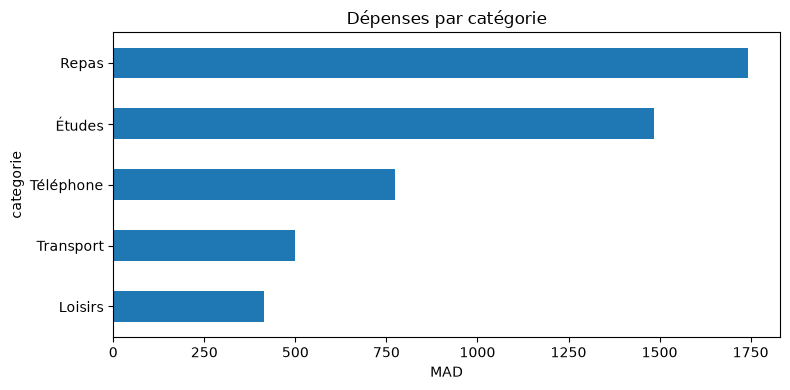

In [6]:
df_analyse.groupby("categorie")["montant_mad"].sum().sort_values().plot(kind="barh", figsize=(8,4))
plt.title("Dépenses par catégorie")
plt.xlabel("MAD")
plt.tight_layout()
plt.show()


## Exporter le résultat nettoyé

In [7]:
df_clean.to_csv("donnees_nettoyees.csv", index=False, encoding="utf-8-sig")
df_clean.to_excel("donnees_nettoyees.xlsx", index=False)
print("Export terminé.")


Export terminé.


## Exercices à faire seul

1. Formule une question métier supplémentaire à partir de ces données.
2. Écris une commande Pandas pour y répondre.
3. Crée un deuxième graphique différent du premier.
4. Explique en deux phrases ce que tu as appris.
5. Vérifie si les anomalies détectées doivent être corrigées, exclues ou conservées selon le contexte.

**Rappel :** les valeurs sont artificielles et les règles de nettoyage proposées sont pédagogiques. En entreprise, il faut valider les règles métier avant de supprimer ou corriger des lignes.